
# Exploratory Data Analysis
## UCI Default of Credit Card Clients Dataset

### Objective
The objective of this notebook is to explore the UCI Default of Credit Card Clients dataset, understand its feature distributions, identify data quality issues, investigate relationships between customer attributes and payment defaults, and derive insights to guide the development of classification models.

### Dataset Overview
- Dataset: Default of Credit Card Clients
- Total observations: 30,000
- Input features: 23
- Identifier: ID
- Target variable: default payment next month
- Problem type: Binary Classification

In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "default of credit card clients.xls"

print("Libraries imported successfully.")
print("Project root:", PROJECT_ROOT)

Libraries imported successfully.
Project root: /Users/arinirsm/PycharmProjects/BITS-MTech-AIML-ML-Assignment-2


In [2]:
df = pd.read_excel(DATA_PATH, header=1, engine="calamine")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

display(df.describe().T)
print("\nStatistical summary:")

Dataset dimensions: (30000, 25)

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Data types:


ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0



Statistical summary:


## 2. Data Quality Assessment

This section examines missing values, duplicate records, and potentially invalid categorical values to understand the quality of the dataset before model development.

In [5]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Unique values in categorical features
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

for column in categorical_features:
    print(f"\n{column} unique values:")
    print(sorted(df[column].unique()))

# Unique target values
target = "default payment next month"

print("\nTarget classes:")
print(sorted(df[target].unique()))

Missing values per column:


ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total missing values: 0

Duplicate rows: 0

SEX unique values:
[np.int64(1), np.int64(2)]

EDUCATION unique values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

MARRIAGE unique values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Target classes:
[np.int64(0), np.int64(1)]


### Observations

- The dataset contains no missing values across its 25 columns.
- No duplicate records were identified.
- The `SEX` feature contains two distinct encoded categories.
- The `EDUCATION` feature contains values from 0 to 6, while `MARRIAGE` contains values from 0 to 3. These categories will be examined during preprocessing.
- The target variable contains two classes, confirming that this is a binary classification problem.

## 3. Target Variable Distribution

The target variable indicates whether a customer defaulted on their next payment. Understanding its class distribution is important because an imbalanced dataset can affect classification performance.

,Count,Percentage
default payment next month,,
0,23364,77.88
1,6636,22.12


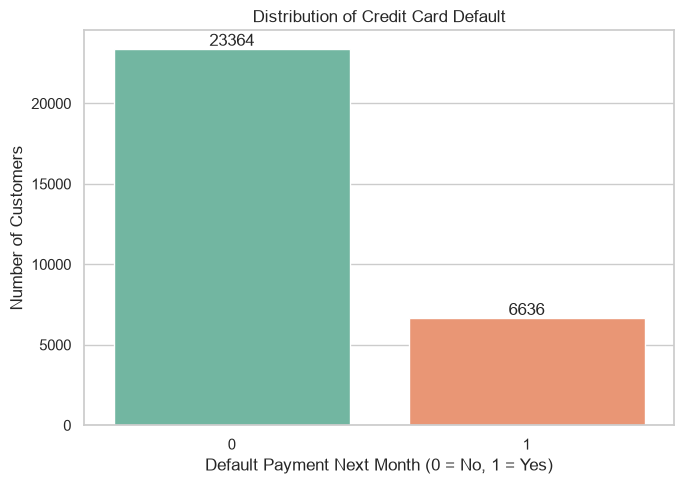

In [7]:
target_counts = df[target].value_counts().sort_index()
target_percentages = df[target].value_counts(normalize=True).sort_index() * 100

distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(distribution)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=target, hue=target, palette="Set2", legend=False)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Payment Next Month (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Observations

- 23,364 customers (77.88%) belong to the non-default class.
- 6,636 customers (22.12%) belong to the default class.
- The dataset exhibits moderate class imbalance, with non-default customers substantially outnumbering default customers.

This imbalance makes accuracy alone insufficient for evaluating model performance. Precision, recall, F1-score, ROC-AUC and Matthews Correlation Coefficient (MCC) will also be considered during model evaluation.

## 4. Univariate Analysis

This section examines the distributions of customer credit limits, age, bill amounts and payment amounts to understand the characteristics and spread of the dataset.

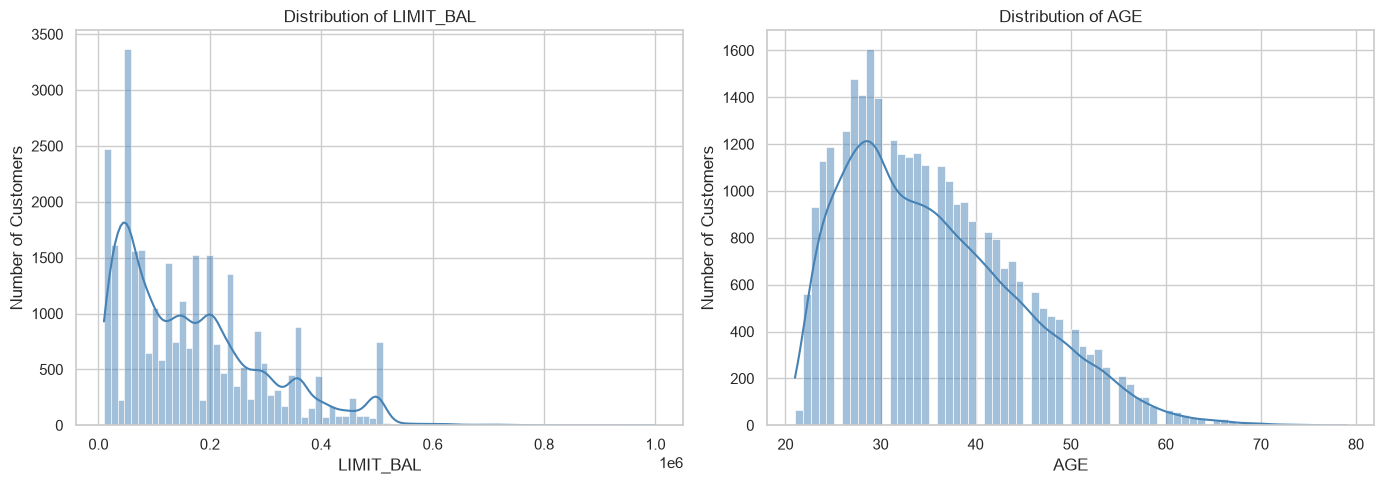

In [8]:
# Features selected for distribution analysis
features = ["LIMIT_BAL", "AGE"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, features):
    sns.histplot(data=df, x=feature, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

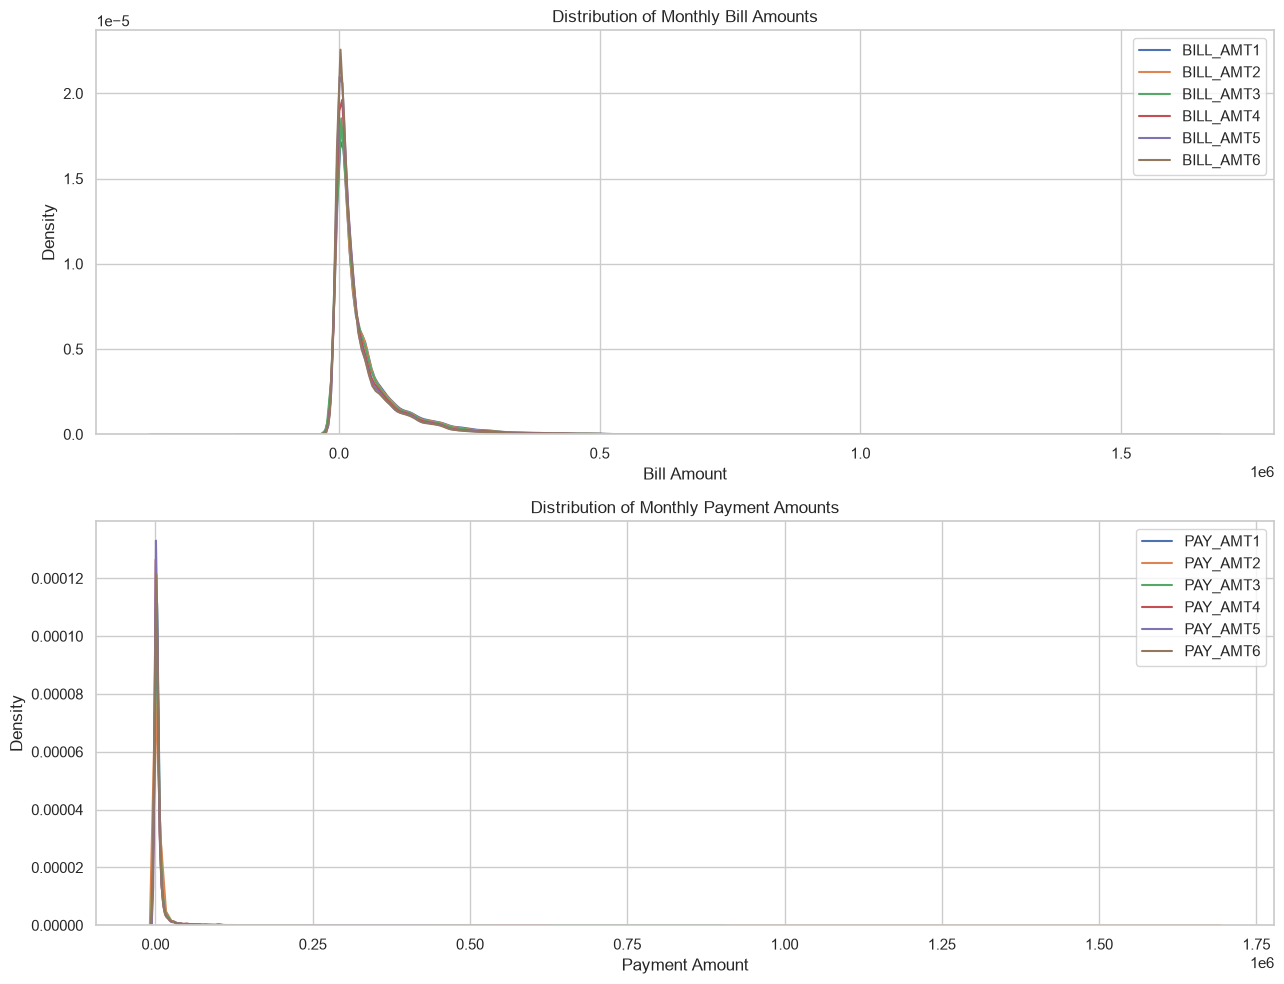

In [9]:
bill_features = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_features = [f"PAY_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 1, figsize=(13, 10))

for feature in bill_features:
    sns.kdeplot(data=df, x=feature, ax=axes[0], label=feature)

axes[0].set_title("Distribution of Monthly Bill Amounts")
axes[0].set_xlabel("Bill Amount")
axes[0].legend()

for feature in payment_features:
    sns.kdeplot(data=df, x=feature, ax=axes[1], label=feature)

axes[1].set_title("Distribution of Monthly Payment Amounts")
axes[1].set_xlabel("Payment Amount")
axes[1].legend()

plt.tight_layout()
plt.show()

### Observations from Univariate Analysis

1. **Credit Limit:** The `LIMIT_BAL` distribution is positively skewed, indicating that most customers have relatively lower credit limits, while a smaller proportion have substantially higher limits.

2. **Age:** Customer ages are concentrated primarily between 25 and 40 years, with fewer observations among older age groups.

3. **Bill Amounts:** Monthly bill amount distributions exhibit strong positive skewness and contain extreme values. Negative bill amounts are also present in the dataset.

4. **Payment Amounts:** Monthly payment amounts are highly right-skewed, with most customers making relatively smaller payments and a few making considerably larger payments.

5. **Preprocessing Implications:** The financial features exhibit different scales and substantial skewness. Feature scaling will therefore be important for distance-based and gradient-based classification algorithms. Extreme values will be investigated further before deciding on any treatment.

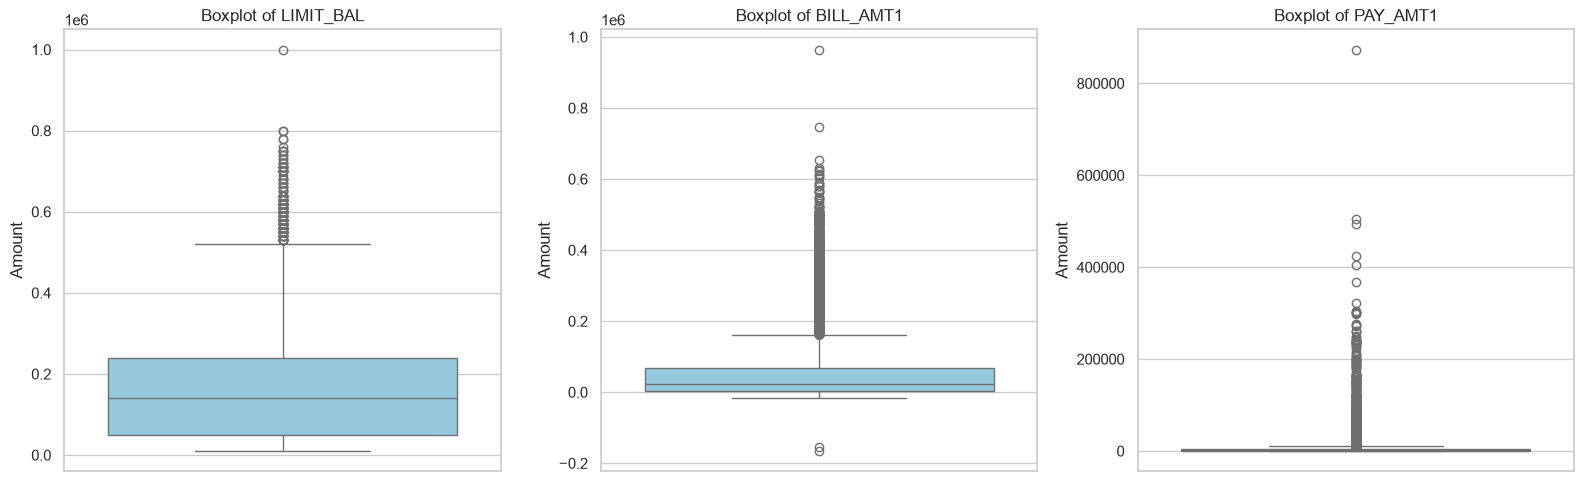

In [10]:
# Boxplots for financial features
financial_features = [
    "LIMIT_BAL",
    "BILL_AMT1",
    "PAY_AMT1"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, financial_features):
    sns.boxplot(y=df[feature], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {feature}")
    ax.set_ylabel("Amount")

plt.tight_layout()
plt.show()


### Observations from Outlier Analysis

1. **Credit Limit:** The `LIMIT_BAL` feature contains several high-value observations beyond the upper whisker, indicating variability in the credit limits assigned to customers.

2. **Bill Amount:** `BILL_AMT1` exhibits substantial dispersion and numerous statistical outliers. Both positive and negative bill amounts are present.

3. **Payment Amount:** `PAY_AMT1` contains a large number of observations beyond the upper whisker, with a few exceptionally high payment values.

4. **Preprocessing Considerations:** These observations will not be removed solely because they are classified as outliers. Their influence will be considered during preprocessing and model evaluation. Feature scaling will be applied where required by the classification algorithms.


## 5. Repayment Status Analysis

This section examines customers' historical repayment status across six months and investigates how repayment behaviour is associated with the target variable.


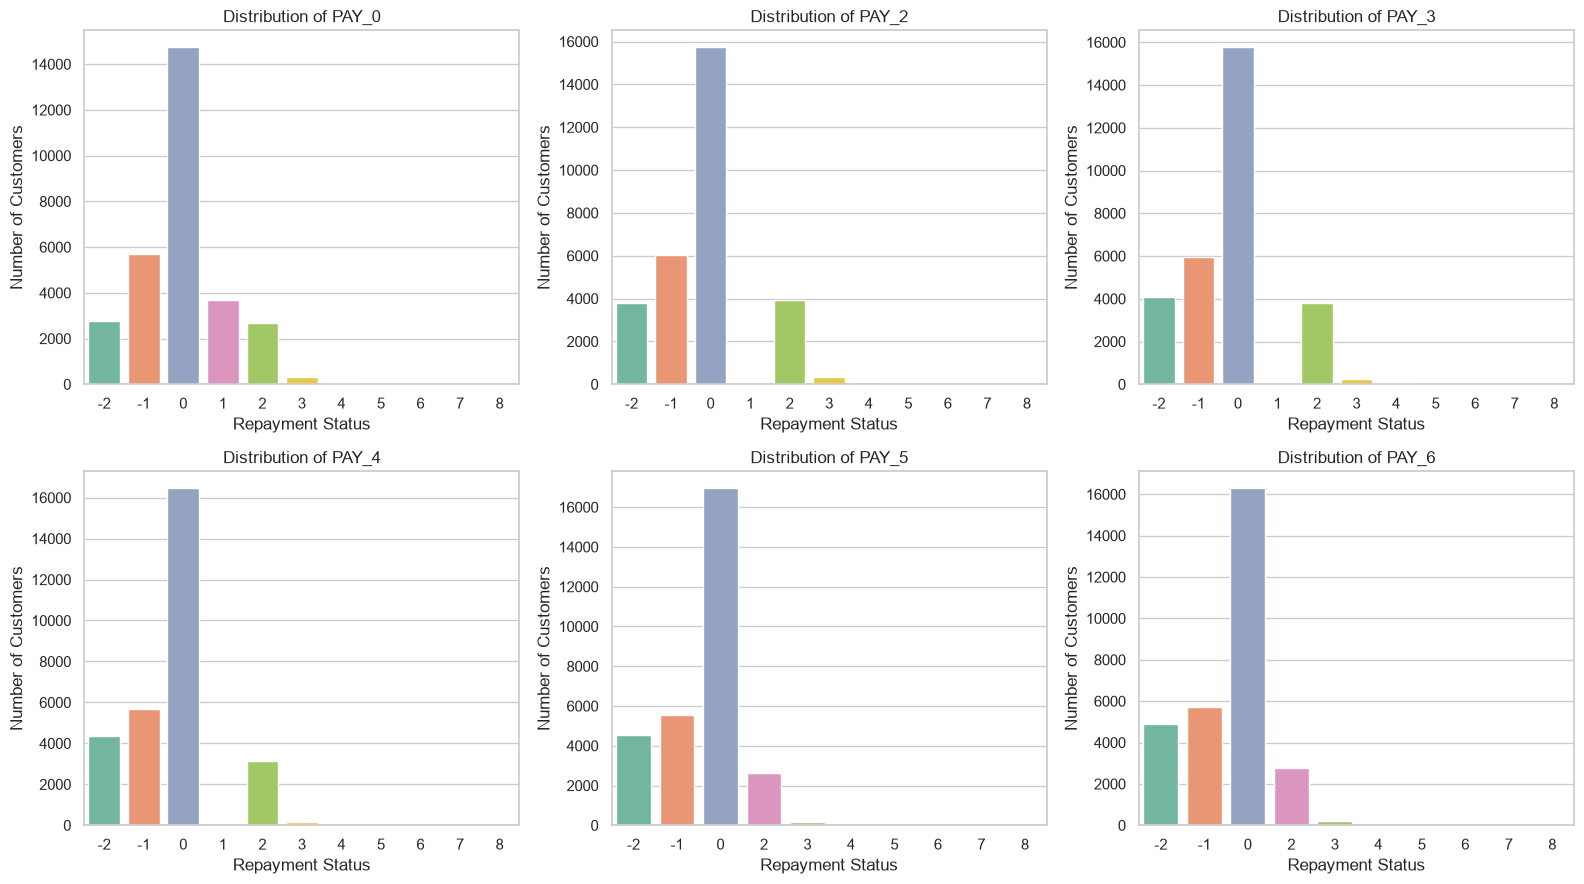

In [11]:

pay_features = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), pay_features):
    sns.countplot(
        data=df,
        x=feature,
        hue=feature,
        order=sorted(df[feature].unique()),
        palette="Set2",
        legend=False,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Repayment Status")
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

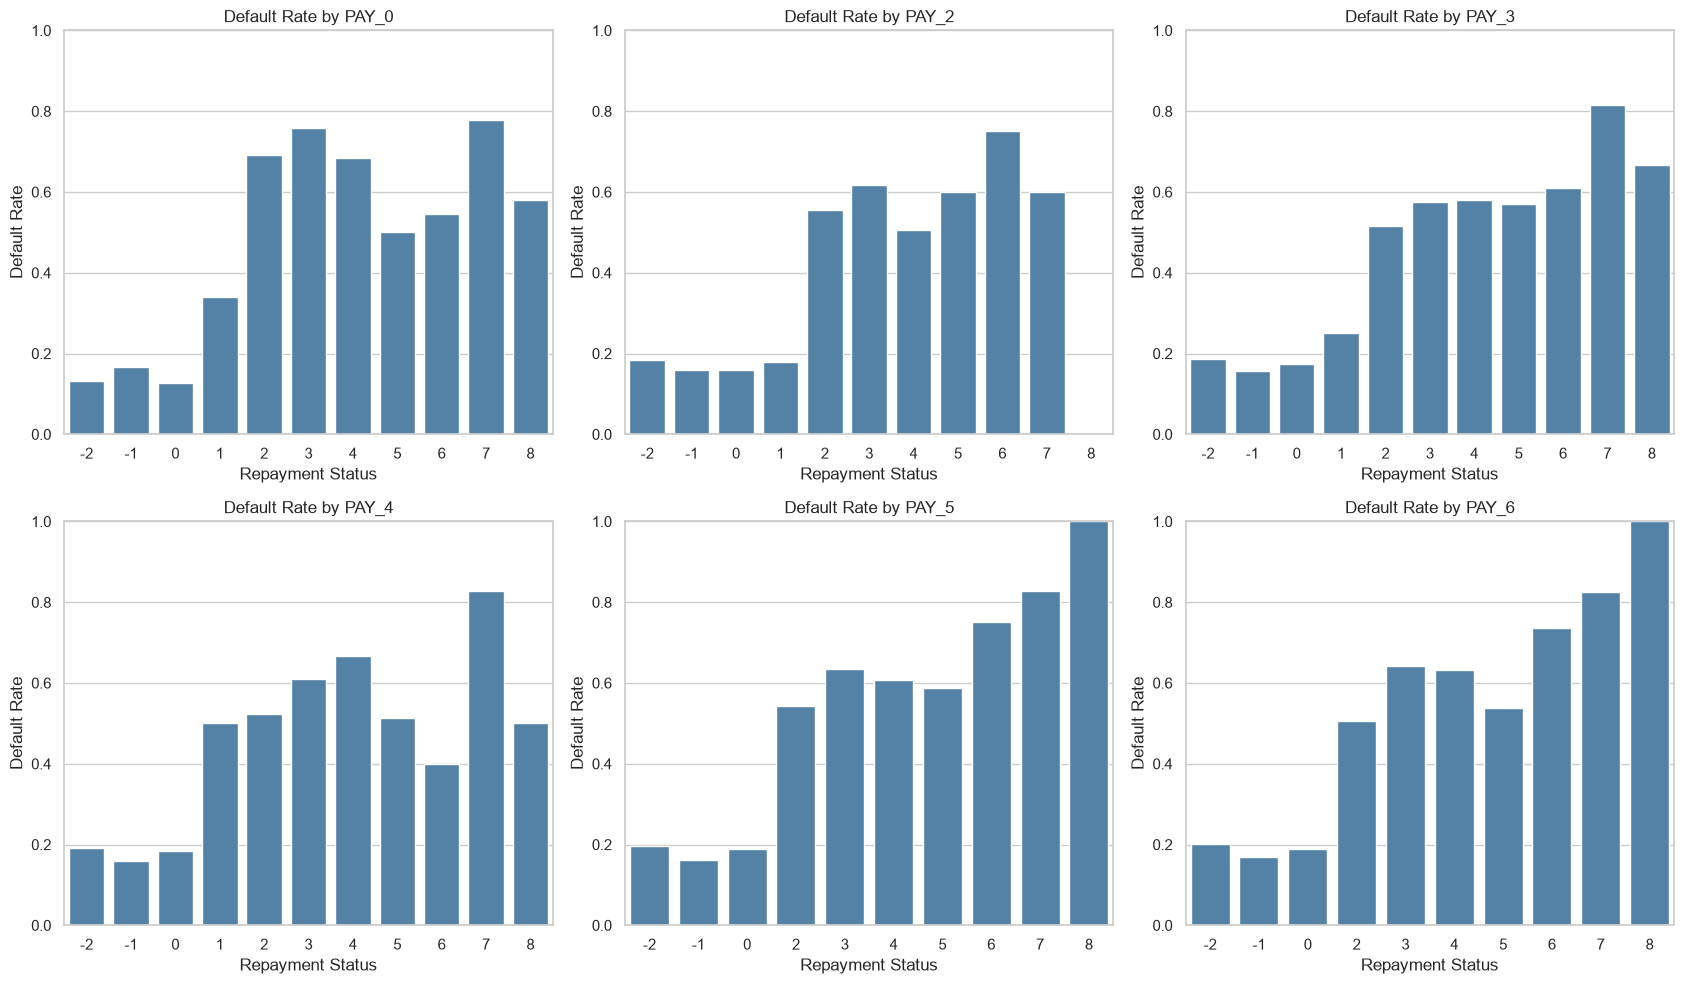

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, feature in zip(axes.flatten(), pay_features):
    sns.barplot(
        data=df,
        x=feature,
        y="default payment next month",
        errorbar=None,
        ax=ax,
        color="steelblue"
    )
    ax.set_title(f"Default Rate by {feature}")
    ax.set_xlabel("Repayment Status")
    ax.set_ylabel("Default Rate")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 4. Feature Distribution and Relationship Analysis

### Credit Limit and Age
The credit limit distribution is positively skewed, indicating that most customers have relatively lower credit limits, while a smaller proportion have substantially higher limits. Customer ages are primarily concentrated between approximately 25 and 40 years.

### Bill and Payment Amounts
The monthly bill and payment amount variables exhibit positively skewed distributions with several extreme observations. These patterns indicate considerable variation in customer billing and payment behaviour. The extreme observations are retained for further modelling rather than being removed solely based on statistical outlier detection.

### Repayment Status
The repayment status variables (`PAY_0`, `PAY_2` to `PAY_6`) show that status 0 is the most frequently observed category. The distributions also indicate variation in repayment behaviour across the six recorded months.

### Relationship Between Repayment Status and Default
The default-rate visualisations indicate an increasing tendency towards default among customers with more severe repayment delays. This suggests that historical repayment behaviour may be an important predictor of future credit card default.

## 5. Key EDA Findings

1. The dataset contains 30,000 observations and 23 input features, along with an identifier and binary target variable.
2. No missing values or duplicate records were identified.
3. The target variable is imbalanced: 77.88% non-default observations and 22.12% default observations.
4. Credit limits, bill amounts, and payment amounts exhibit skewness and extreme values.
5. Historical repayment status appears to have a meaningful relationship with the target variable.

These findings will guide preprocessing, model selection, and evaluation. In particular, stratified train-test splitting and multiple evaluation metrics will be used to account for the imbalanced target distribution.

## 6. Default Rate by Customer Demographics

### 6.1 Default Rate by Gender

This analysis examines whether the proportion of customers who default varies across the gender categories.

   SEX  count  default_rate
0    1  11888     24.167227
1    2  18112     20.776281


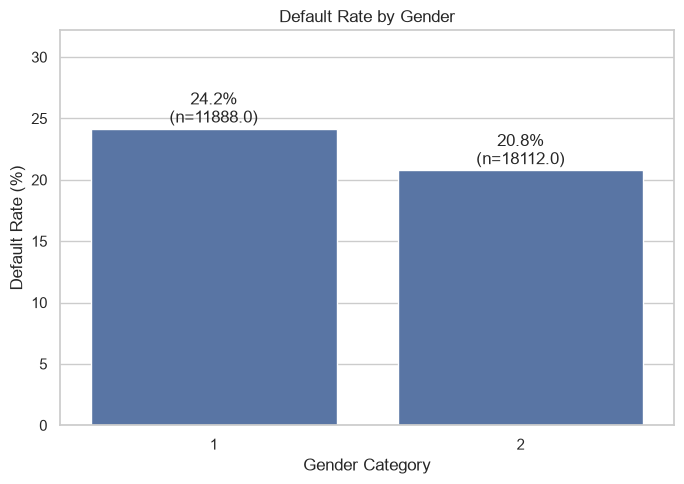

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = "default payment next month"

sex_analysis = (
    df.groupby("SEX")[TARGET]
    .agg(["count", "mean"])
    .reset_index()
)

sex_analysis["default_rate"] = sex_analysis["mean"] * 100

print(sex_analysis[["SEX", "count", "default_rate"]])

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=sex_analysis,
    x="SEX",
    y="default_rate"
)

for i, row in sex_analysis.iterrows():
    ax.text(
        i,
        row["default_rate"] + 0.5,
        f'{row["default_rate"]:.1f}%\n(n={row["count"]})',
        ha="center"
    )

plt.title("Default Rate by Gender")
plt.xlabel("Gender Category")
plt.ylabel("Default Rate (%)")
plt.ylim(0, sex_analysis["default_rate"].max() + 8)
plt.tight_layout()
plt.show()

### 6.2 Default Rate by Education Level

This analysis investigates the relationship between customers' education categories and their credit card default behaviour.

   EDUCATION  count  default_rate
0          0     14      0.000000
1          1  10585     19.234766
2          2  14030     23.734854
3          3   4917     25.157616
4          4    123      5.691057
5          5    280      6.428571
6          6     51     15.686275


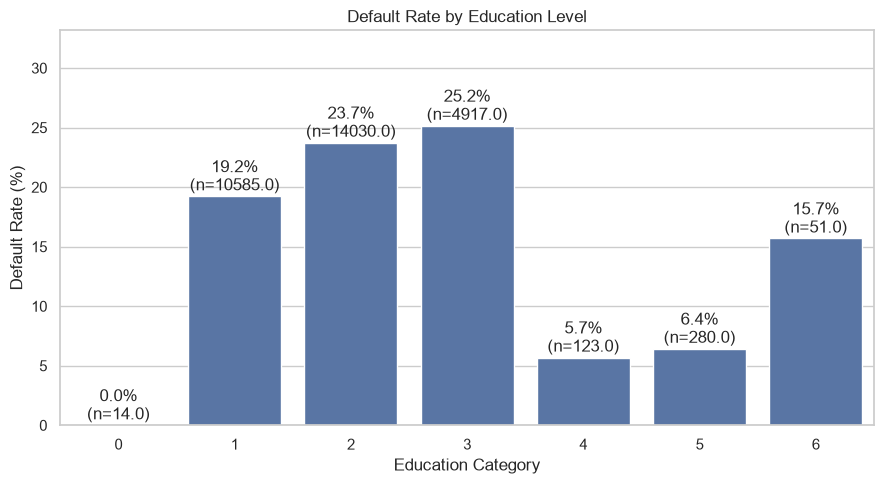

In [15]:
education_analysis = (
    df.groupby("EDUCATION")[TARGET]
    .agg(["count", "mean"])
    .reset_index()
)

education_analysis["default_rate"] = education_analysis["mean"] * 100

print(education_analysis[["EDUCATION", "count", "default_rate"]])

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=education_analysis,
    x="EDUCATION",
    y="default_rate"
)

for i, row in education_analysis.iterrows():
    ax.text(
        i,
        row["default_rate"] + 0.5,
        f'{row["default_rate"]:.1f}%\n(n={row["count"]})',
        ha="center"
    )

plt.title("Default Rate by Education Level")
plt.xlabel("Education Category")
plt.ylabel("Default Rate (%)")
plt.ylim(0, education_analysis["default_rate"].max() + 8)
plt.tight_layout()
plt.show()

### 6.3 Default Rate by Marital Status

This analysis explores whether default rates differ across the marital-status categories in the dataset.

   MARRIAGE  count  default_rate
0         0     54      9.259259
1         1  13659     23.471704
2         2  15964     20.928339
3         3    323     26.006192


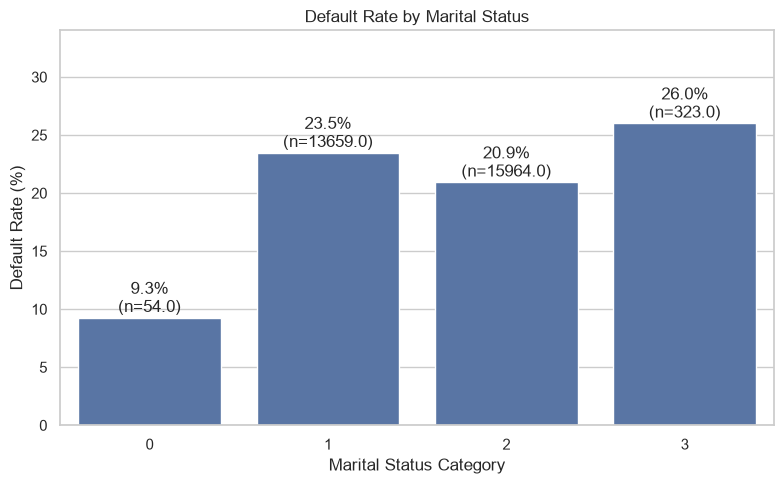

In [16]:
marriage_analysis = (
    df.groupby("MARRIAGE")[TARGET]
    .agg(["count", "mean"])
    .reset_index()
)

marriage_analysis["default_rate"] = marriage_analysis["mean"] * 100

print(marriage_analysis[["MARRIAGE", "count", "default_rate"]])

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=marriage_analysis,
    x="MARRIAGE",
    y="default_rate"
)

for i, row in marriage_analysis.iterrows():
    ax.text(
        i,
        row["default_rate"] + 0.5,
        f'{row["default_rate"]:.1f}%\n(n={row["count"]})',
        ha="center"
    )

plt.title("Default Rate by Marital Status")
plt.xlabel("Marital Status Category")
plt.ylabel("Default Rate (%)")
plt.ylim(0, marriage_analysis["default_rate"].max() + 8)
plt.tight_layout()
plt.show()

### 6.4 Summary of Categorical Feature Analysis

In [17]:
categorical_summary = pd.concat([
    sex_analysis.assign(feature="SEX"),
    education_analysis.assign(feature="EDUCATION"),
    marriage_analysis.assign(feature="MARRIAGE")
], ignore_index=True)

categorical_summary = categorical_summary[
    ["feature", "SEX", "EDUCATION", "MARRIAGE", "count", "default_rate"]
]

print(categorical_summary.to_string(index=False))

  feature  SEX  EDUCATION  MARRIAGE  count  default_rate
      SEX  1.0        NaN       NaN  11888     24.167227
      SEX  2.0        NaN       NaN  18112     20.776281
EDUCATION  NaN        0.0       NaN     14      0.000000
EDUCATION  NaN        1.0       NaN  10585     19.234766
EDUCATION  NaN        2.0       NaN  14030     23.734854
EDUCATION  NaN        3.0       NaN   4917     25.157616
EDUCATION  NaN        4.0       NaN    123      5.691057
EDUCATION  NaN        5.0       NaN    280      6.428571
EDUCATION  NaN        6.0       NaN     51     15.686275
 MARRIAGE  NaN        NaN       0.0     54      9.259259
 MARRIAGE  NaN        NaN       1.0  13659     23.471704
 MARRIAGE  NaN        NaN       2.0  15964     20.928339
 MARRIAGE  NaN        NaN       3.0    323     26.006192


In [18]:
summary_tables = []

for feature in ["SEX", "EDUCATION", "MARRIAGE"]:
    temp = (
        df.groupby(feature)[TARGET]
        .agg(customer_count="count", default_rate="mean")
        .reset_index()
    )

    temp["default_rate"] *= 100
    temp.insert(0, "feature", feature)
    temp = temp.rename(columns={feature: "category"})

    summary_tables.append(temp)

categorical_summary = pd.concat(summary_tables, ignore_index=True)

print(categorical_summary.round(2).to_string(index=False))

  feature  category  customer_count  default_rate
      SEX         1           11888         24.17
      SEX         2           18112         20.78
EDUCATION         0              14          0.00
EDUCATION         1           10585         19.23
EDUCATION         2           14030         23.73
EDUCATION         3            4917         25.16
EDUCATION         4             123          5.69
EDUCATION         5             280          6.43
EDUCATION         6              51         15.69
 MARRIAGE         0              54          9.26
 MARRIAGE         1           13659         23.47
 MARRIAGE         2           15964         20.93
 MARRIAGE         3             323         26.01


                            Customer_Count  Percentage
default payment next month                            
0                                    23364       77.88
1                                     6636       22.12


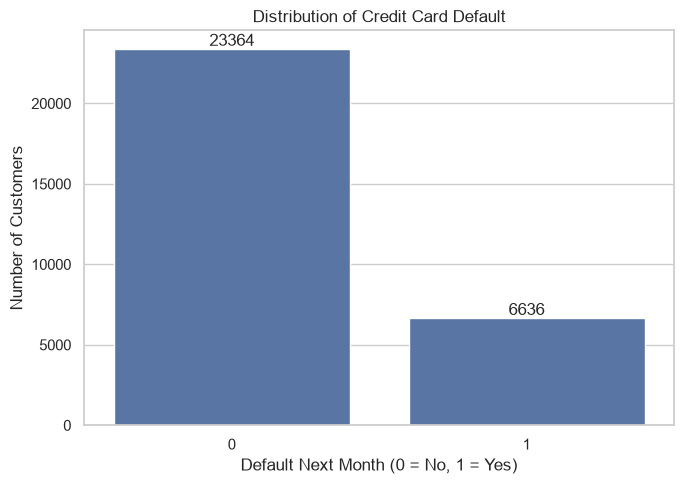

In [26]:
# Target class distribution

TARGET = 'default payment next month'

target_counts = df[TARGET].value_counts().sort_index()
target_percentages = (
    df[TARGET].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    'Customer_Count': target_counts,
    'Percentage': target_percentages
})

print(target_summary.round(2))

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x=TARGET)

plt.title('Distribution of Credit Card Default')
plt.xlabel('Default Next Month (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

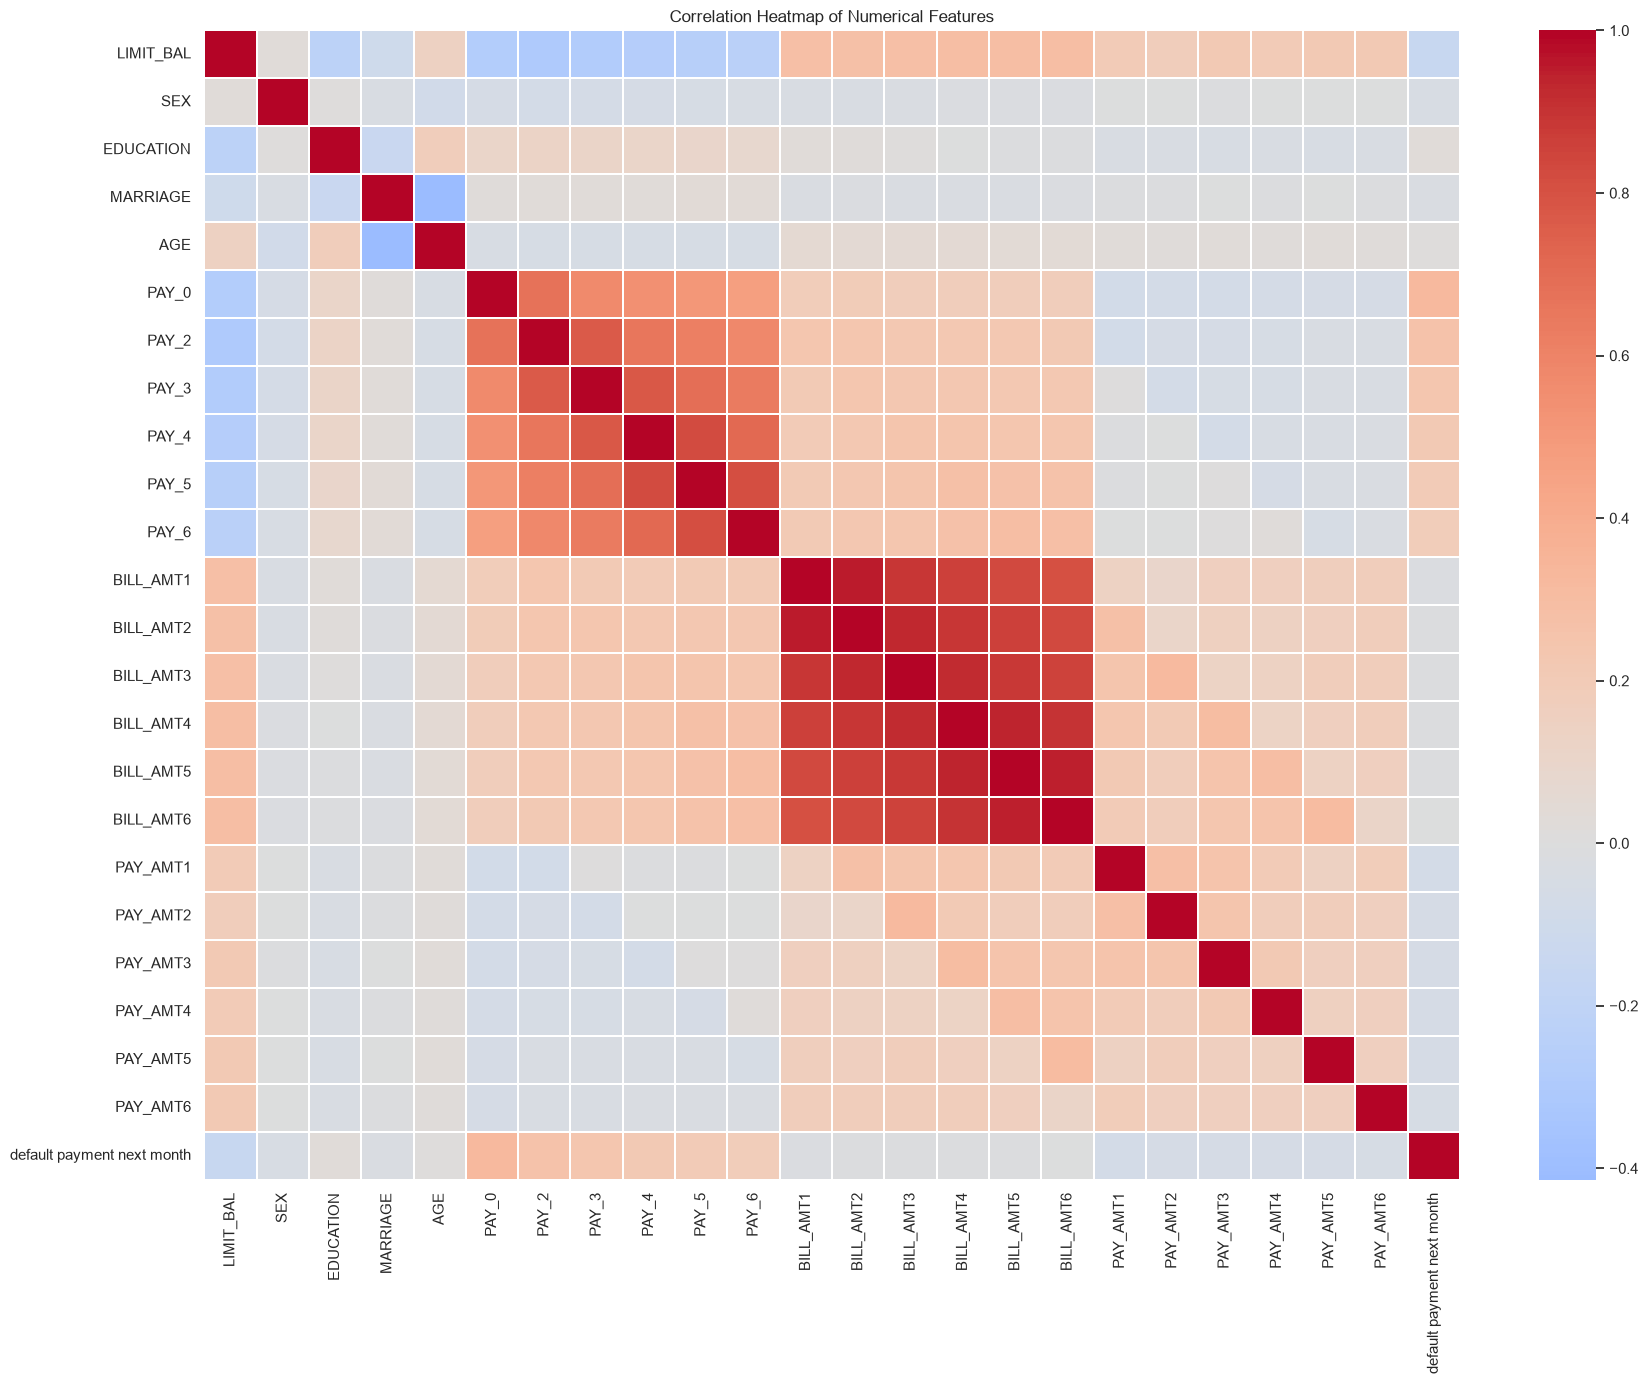

In [27]:
# Correlation analysis

numeric_df = df.select_dtypes(include=['number']).drop(
    columns=['ID', 'AGE_GROUP'],
    errors='ignore'
)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

  AGE_GROUP  count  default_rate
0     21-30  11013         22.44
1     31-40  10713         20.43
2     41-50   6005         23.30
3     51-60   1997         25.24
4     61-79    272         26.84


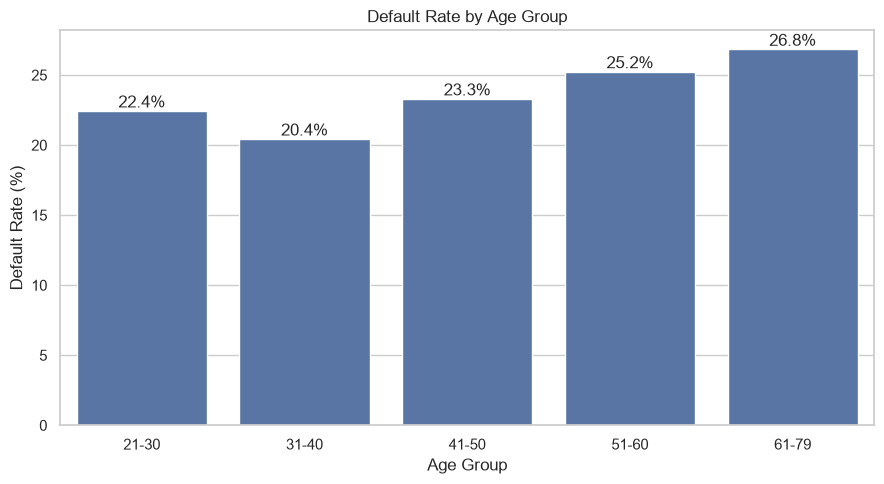

In [28]:
# Default rate by age group

age_default = (
    df.groupby('AGE_GROUP', observed=False)[TARGET]
    .agg(['count', 'mean'])
    .reset_index()
)

age_default['default_rate'] = age_default['mean'] * 100

print(age_default[['AGE_GROUP', 'count', 'default_rate']].round(2))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_default,
    x='AGE_GROUP',
    y='default_rate'
)

plt.title('Default Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Default Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.tight_layout()
plt.show()

In [29]:
# Data quality checks

print("Dataset shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df[TARGET].value_counts())

print("\nDataset information:")
df.info()

Dataset shape: (30000, 26)

Missing values: 0

Duplicate rows: 0

Target distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   ID                          30000 non-null  int64   
 1   LIMIT_BAL                   30000 non-null  int64   
 2   SEX                         30000 non-null  int64   
 3   EDUCATION                   30000 non-null  int64   
 4   MARRIAGE                    30000 non-null  int64   
 5   AGE                         30000 non-null  int64   
 6   PAY_0                       30000 non-null  int64   
 7   PAY_2                       30000 non-null  int64   
 8   PAY_3                       30000 non-null  int64   
 9   PAY_4                       30000 non-null  int64   
 10  PAY_5            

In [30]:
# Final EDA Summary

target_column = 'default payment next month'

total_customers = len(df)
default_count = df[target_column].sum()
non_default_count = total_customers - default_count

print("========== EXPLORATORY DATA ANALYSIS SUMMARY ==========")

print(f"\nTotal customers: {total_customers}")
print(f"Total features (excluding target): {df.shape[1] - 1}")

print("\nDATA QUALITY")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate records: {df.duplicated().sum()}")

print("\nTARGET DISTRIBUTION")
print(f"Non-default customers: {non_default_count} "
      f"({non_default_count / total_customers * 100:.2f}%)")

print(f"Default customers: {default_count} "
      f"({default_count / total_customers * 100:.2f}%)")

print("\nNUMERICAL FEATURE OBSERVATIONS")
print("Financial variables exhibit skewness and outliers.")
print("Repayment status variables contain useful historical payment information.")

print("\nCATEGORICAL FEATURE OBSERVATIONS")
print("Default rates vary across gender, education and marital status categories.")

print("\nCONCLUSION")
print("The dataset is suitable for binary classification.")
print("Class imbalance must be considered during model evaluation.")
print("Feature preprocessing and appropriate model evaluation metrics "
      "will be important in the next stage.")

print("\n=======================================================")

========== EXPLORATORY DATA ANALYSIS SUMMARY ==========

Total customers: 30000
Total features (excluding target): 25

DATA QUALITY
Missing values: 0
Duplicate records: 0

TARGET DISTRIBUTION
Non-default customers: 23364 (77.88%)
Default customers: 6636 (22.12%)

NUMERICAL FEATURE OBSERVATIONS
Financial variables exhibit skewness and outliers.
Repayment status variables contain useful historical payment information.

CATEGORICAL FEATURE OBSERVATIONS
Default rates vary across gender, education and marital status categories.

CONCLUSION
The dataset is suitable for binary classification.
Class imbalance must be considered during model evaluation.
Feature preprocessing and appropriate model evaluation metrics will be important in the next stage.

